# Student Marks Prediction using Multiple Linear Regression
### A hands-on mini project

**Goal:** predict a student's final exam mark from study hours, attendance, assignment average, previous exam mark, and sleep hours.

This follows the same structure as the reference notebook's Multiple Linear Regression section.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use('seaborn-v0_8-whitegrid')

---
# Part 1 — Multiple Linear Regression

## 1.1 Create and check the student data

The sample contains 200 students. A fixed random seed makes the project reproducible.

In [2]:
rng = np.random.default_rng(42)
student_count = 200

df = pd.DataFrame({
    'study_hours_per_week': rng.uniform(2, 25, student_count),
    'attendance_percent': rng.uniform(55, 100, student_count),
    'assignment_average': rng.uniform(45, 100, student_count),
    'previous_exam_mark': rng.uniform(35, 100, student_count),
    'sleep_hours_per_night': rng.uniform(5, 9, student_count)
})

df['final_exam_mark'] = (
    4 + 1.15 * df['study_hours_per_week']
    + 0.22 * df['attendance_percent']
    + 0.24 * df['assignment_average']
    + 0.30 * df['previous_exam_mark']
    + 1.8 * df['sleep_hours_per_night']
    + rng.normal(0, 5, student_count)
).clip(0, 100)

df.to_csv('student_marks.csv', index=False)
df.head()

,study_hours_per_week,attendance_percent,assignment_average,previous_exam_mark,sleep_hours_per_night,final_exam_mark
0,19.800989,89.983218,61.606007,66.037882,7.954322,91.771070
1,12.094204,98.732189,95.514304,84.493117,6.268613,100.000000
2,21.747752,77.533353,87.971172,93.716312,8.560078,100.000000
3,18.039465,61.475388,51.082363,81.845237,7.375322,86.944909
4,4.166079,55.627133,99.836906,97.608730,5.504105,83.648916


In [3]:
df.isnull().sum()  # quick preprocessing check

study_hours_per_week     0
attendance_percent       0
assignment_average       0
previous_exam_mark       0
sleep_hours_per_night    0
final_exam_mark          0
dtype: int64

## 1.2 Train/test split with five features

`X` contains the input features. `y` is the final exam mark we want to predict.

In [4]:
feature_cols = [
    'study_hours_per_week', 'attendance_percent', 'assignment_average',
    'previous_exam_mark', 'sleep_hours_per_night'
]
X = df[feature_cols]
y = df['final_exam_mark']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print('Training rows:', X_train.shape[0], '| Features per student:', X_train.shape[1])
print('Test rows:', X_test.shape[0])

Training rows: 160 | Features per student: 5
Test rows: 40


## 1.3 Fit the model

The model learns one weight for each input feature and one bias (intercept).

In [5]:
model = LinearRegression()
model.fit(X_train, y_train)

for name, weight in zip(feature_cols, model.coef_):
    print(f'w for {name}: {weight:.3f}')
print(f'bias (b): {model.intercept_:.3f}')

w for study_hours_per_week: 1.112
w for attendance_percent: 0.184
w for assignment_average: 0.188
w for previous_exam_mark: 0.275
w for sleep_hours_per_night: 1.623
bias (b): 13.030


## 1.4 What each weight means

Each weight describes the effect of one feature **while the other features stay fixed**.

In [6]:
for name, weight in zip(feature_cols, model.coef_):
    direction = 'increases' if weight >= 0 else 'decreases'
    print(f'Holding other factors fixed, one extra unit of {name} {direction} the predicted mark by about {abs(weight):.2f} marks.')

Holding other factors fixed, one extra unit of study_hours_per_week increases the predicted mark by about 1.11 marks.
Holding other factors fixed, one extra unit of attendance_percent increases the predicted mark by about 0.18 marks.
Holding other factors fixed, one extra unit of assignment_average increases the predicted mark by about 0.19 marks.
Holding other factors fixed, one extra unit of previous_exam_mark increases the predicted mark by about 0.27 marks.
Holding other factors fixed, one extra unit of sleep_hours_per_night increases the predicted mark by about 1.62 marks.


## 1.5 Evaluate the model

The test students were not used when fitting the model.

In [7]:
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print(f'MAE:  {mae:.2f} marks')
print(f'RMSE: {rmse:.2f} marks')
print(f'R2:   {r2:.3f}')

MAE:  3.10 marks
RMSE: 4.02 marks
R2:   0.886


## 1.6 Prediction values for five students

Marks are rounded to whole numbers, as requested.

In [8]:
five_predictions = pd.DataFrame({
    'actual_final_mark': np.rint(y_test).astype(int),
    'predicted_final_mark': np.rint(y_pred).astype(int)
}).head(5)
five_predictions.index.name = 'student_number'
five_predictions.to_csv('prediction_values.csv')
five_predictions

,actual_final_mark,predicted_final_mark
student_number,,
95,96,96
15,87,85
30,100,102
158,84,84
128,87,79


## 1.7 Visualize results

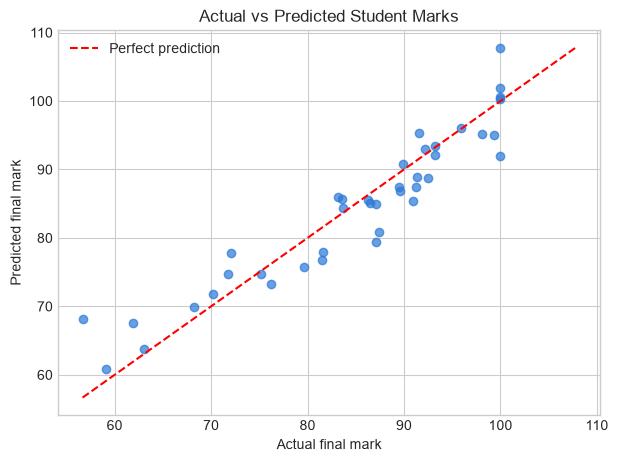

In [9]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.7, color='#2a78d6')
limits = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(limits, limits, 'r--', label='Perfect prediction')
plt.xlabel('Actual final mark')
plt.ylabel('Predicted final mark')
plt.title('Actual vs Predicted Student Marks')
plt.legend()
plt.show()

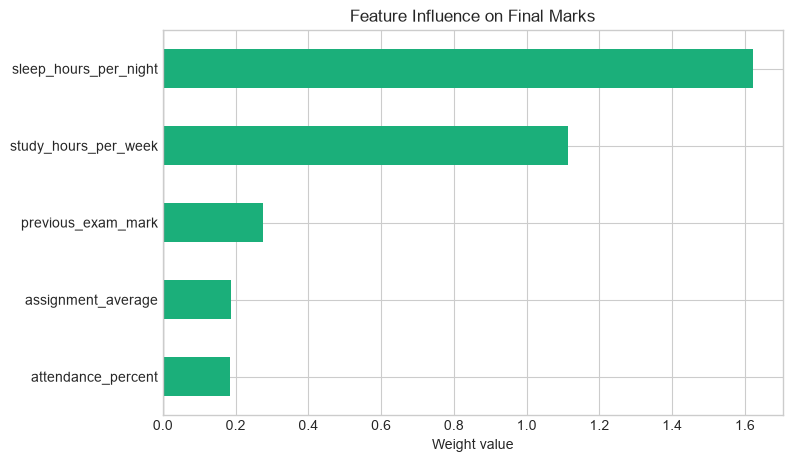

In [10]:
coefficients = pd.Series(model.coef_, index=feature_cols).sort_values()
coefficients.plot(kind='barh', figsize=(8, 5), color='#1baf7a')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Weight value')
plt.title('Feature Influence on Final Marks')
plt.show()

---
## Recap

- Multiple regression uses several features to predict one numerical target.
- The equation is: `final mark = w1x1 + w2x2 + ... + w5x5 + b`.
- Each weight is interpreted while all other features are held fixed.
- MAE and RMSE measure prediction error; R² measures how much variation the model explains.
- This dataset is generated for learning, not for real academic decisions.